## Beat-Interval Filtering
This notebook will exist to turn the EmotiBit's PPG-derived beat data into a single, usable dataframe that will flag 10-second windows of time into one of two quality-control categories:
- Acceptable -> The detected beats in this window pass all of the PPG quality checks below, so HRV from this window can be trusted.
- Unacceptable -> At least one check fails, so the beats in this window are likely missed, extra or implausible.

There is no Shaky category. The checks from the source below are pass/fail and the paper gives no margin around its thresholds, so adding one would be inventing a threshold.

### Files Used
- `data-files\2.1_G1_ground_truth_BI.csv` -> Beat Interval: time in ms between successive heartbeats, as detected by the EmotiBit from its PPG signal. One row per detected beat.
- `data-files\2.1_G1_ground_truth_PG.csv` -> PPG Green. Only its timestamps are used here, to find the start and end of the PPG recording.
- `data-files\2.1_G1_biometrics.csv` -> Contains phase markers
- `processed-data\2.1_G1_movement_mask.csv` -> Movement mask from `001_movement-artifacts.ipynb`, used only for a cross-check

### Important Notes On Measurement Variables
- PPG Green has shallow penetration depth. It's primary use is for heart rate and HRV data. It is also less prone to movement artifacts. This is something to consider later(later down the line we can implment more variable-specific QC and cleaning rules). PPG Green, along with Polar ECG measurements in the future, should be our main HRV metrics.
- PPG Red has moderate penetration depth. More susceptible to ambient light interference and movement artifacts. It's most commonly used on patients who are remaining completely still. However, if the participant is sitting still and only doing a minor task like typing or talking, we can use this with caution.
- PPG Infrared has deep penetration depth. It is also significantly less affected by skin tone. However, it can pick up noise from deeper tissues like muscle fibers and is also susceptible to movement artifacts. It's most commonly used on patients who are remaining completely still. However, if the participant is sitting still and only doing a minor task like typing or talking, we can use this with caution.

### Sources I'm Using To Determine QC Thresholds

#### Source 1
`https://pmc.ncbi.nlm.nih.gov/articles/PMC12213893/` \
They divided PPG recordings into 10-second windows and used the following measures to check quality of data:
| Quality check | Threshold used in the paper | What it means |
|---|---|---|
| Physiologically plausible heart rate | 30–180 BPM | Reject epochs producing implausible heart-rate estimates outside this range. |
| Maximum gap between successive pulse peaks | ≤ 3 seconds | Reject epochs with gaps exceeding 3 seconds, which could indicate missed beats. |
| Beat-to-beat interval ratio | < 2.2 | The maximum interval divided by the minimum interval within an epoch must be less than 2.2. |
| PPG signal similarity(Not Using For Now) | Correlation coefficient ≥ 0.86 | The average pulse waveform must sufficiently resemble the template waveform. |

Elaboration on PPG Signal Similarity: \
The researchers identified peaks in the 10-second window, found the median interval between beats, created a "generic" wave form where the interval between each peak was the previously calculated median interval, then compared that waveform's similarity to the recorded waveform. Basically, they are comparing the actual waveform to a generated template based on what the waveform "should be". This is something we could look into later.

### Assumptions
1. **The device's detected beats (`BI`) are the pulse peaks.** The checks are applied to the beats the EmotiBit detected, not to peaks we detect ourselves, because these are the beat intervals HRV will be calculated from. The EmotiBit docs used here don't say which PPG channel its beat detection uses.
2. **Each `BI` value is the interval ending at that row's timestamp.** Supported by "Loading & Dropping Columns": the time between consecutive beat timestamps matches `BI` closely.
3. **A window's intervals include every interval that overlaps it.** That is all beats inside the window, plus the first beat after it (whose interval runs across the window's end). Without the closing beat, a window whose last few seconds have no beats would never show that gap. A window with no beats at all is then covered by one long interval and fails the gap check.
4. **The window's heart-rate estimate is 60 / mean interval (s).** The paper doesn't say how its estimate was made. The mean of the intervals is the rate implied by the beats the device actually found.
5. **Windows start at the first PPG sample and run back to back.** The last window is shorter than 10 s, and the same checks are applied to it. Windows don't line up with phase boundaries, so each window is labelled with the phase at its start.

### Important Data Processing Steps To Note
**1. Columns kept and dropped.** *(Code: "Loading & Dropping Columns" section.)*
- Kept: `LocalTimestamp` (same clock as `timestamp_unix` in the biometrics file), `EmotiBitTimestamp` and `BI`.
- Dropped: `PacketNumber`, `DataLength`, `TypeTag`, `ProtocolVersion` (packet bookkeeping) and `DataReliability` (100 on every row, so it carries no information).
- No beats are removed. Implausible intervals are handled by the checks, not by removing rows.

**2. The recording is cut into 10 s windows, and the three checks are run on each.** *(Code: "Windowing The Beats" and "Running The Checks" sections.)*
- Heart rate 30–180 BPM, largest interval ≤ 3 s, and largest / smallest interval < 2.2. Signal similarity is not used.
- Acceptable if all three pass, otherwise Unacceptable. Each check's result is kept as its own column.

**3. Phases are attached from the biometrics file.** *(Code: "Attaching Experiment Phases" section.)*
- Same source as `001` and `002`: each window takes the most recent biometrics `event_marker` at or before its start.

**4. Mask: one row per 10 s window.** *(Code: "PPG Mask For HRV Cleaning" section.)*
- `keep` is True for Acceptable windows. Saved to `processed-data/2.1_G1_ppg_mask.csv` for use in `999_hrv-cleaning.ipynb`.

### Global Variables & Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data-files")
BI_FILE = DATA_DIR / "2.1_G1_ground_truth_BI.csv"
PG_FILE = DATA_DIR / "2.1_G1_ground_truth_PG.csv"
BIOMETRICS_FILE = DATA_DIR / "2.1_G1_biometrics.csv"
MOVEMENT_MASK_FILE = Path("../processed-data/2.1_G1_movement_mask.csv")
MASK_OUTPUT_FILE = Path("../processed-data/2.1_G1_IBI_mask.csv")

# Thresholds from Source 1
WINDOW_S = 10
HR_MIN_BPM = 30
HR_MAX_BPM = 180
MAX_GAP_S = 3 # Largest interval allowed (pass if <=)
MAX_INTERVAL_RATIO = 2.2 # Largest / smallest interval (pass if <)

CHECKS = ["hr_ok", "gap_ok", "ratio_ok"]
QUALITY_ORDER = ["Acceptable", "Unacceptable"]
QUALITY_COLORS = {"Acceptable": "#0ca30c", "Unacceptable": "#d03b3b"}

### Loading & Dropping Columns
Loads the beat file and checks Assumption 2: if each `BI` is the interval ending at that beat, the time between consecutive beat timestamps should match `BI`. `LocalTimestamp` is used as the time axis. The check below confirms it moves in step with the EmotiBit's own clock, so using it doesn't distort intervals.

In [2]:
raw = pd.read_csv(BI_FILE)
print(f"DataReliability values: {raw['DataReliability'].value_counts().to_dict()}")
beats = raw[["LocalTimestamp", "EmotiBitTimestamp", "BI"]].copy()

timestamp_step_ms = beats["EmotiBitTimestamp"].diff()
print(f"Beats: {len(beats)}, sorted: {beats['EmotiBitTimestamp'].is_monotonic_increasing}, duplicate timestamps: {beats['EmotiBitTimestamp'].duplicated().sum()}")
print(f"|time between beats - BI|: median {(timestamp_step_ms - beats['BI']).abs().median():.0f} ms, "
      f"99th percentile {(timestamp_step_ms - beats['BI']).abs().quantile(0.99):.0f} ms")
print(f"LocalTimestamp vs EmotiBitTimestamp step difference: max {(beats['LocalTimestamp'].diff() * 1000 - timestamp_step_ms).abs().max():.2f} ms")
print(beats["BI"].describe(percentiles=[.01, .05, .5, .95, .99]).round(0).to_string())

DataReliability values: {100: 5041}
Beats: 5041, sorted: True, duplicate timestamps: 0
|time between beats - BI|: median 4 ms, 99th percentile 20 ms
LocalTimestamp vs EmotiBitTimestamp step difference: max 0.36 ms
count     5041.0
mean      1005.0
std        922.0
min         20.0
1%         414.0
5%         590.0
50%        830.0
95%       2110.0
99%       3920.0
max      29670.0


### Windowing The Beats
The windows run back to back from the first to the last PPG sample (Assumption 5). Each beat's interval runs from `LocalTimestamp - BI` to `LocalTimestamp`. A window's intervals are the beats from the first one at or after the window's start up to the first one at or after its end (Assumption 3).

In [3]:
pg_time = pd.read_csv(PG_FILE, usecols=["LocalTimestamp"])["LocalTimestamp"]
recording_start, recording_end = pg_time.min(), pg_time.max()
window_starts = np.arange(recording_start, recording_end, WINDOW_S)
windows = pd.DataFrame({"window_start": window_starts, "window_end": np.minimum(window_starts + WINDOW_S, recording_end)})

beat_t = beats["LocalTimestamp"].to_numpy()
interval_s = beats["BI"].to_numpy() / 1000
first_beat = np.searchsorted(beat_t, windows["window_start"], side="left")
closing_beat = np.searchsorted(beat_t, windows["window_end"], side="left") # First beat at or after the window end
last_beat = np.minimum(closing_beat, len(beat_t) - 1) # Inclusive. The final window has no closing beat

windows["beats_in_window"] = closing_beat - first_beat
windows["intervals"] = [interval_s[a:b + 1] for a, b in zip(first_beat, last_beat)]

print(f"PPG recording: {(recording_end - recording_start) / 60:.2f} min, {len(windows)} windows "
      f"(last window {windows['window_end'].iloc[-1] - windows['window_start'].iloc[-1]:.1f} s)")
print(f"Windows with no beat inside them: {(windows['beats_in_window'] == 0).sum()}")

PPG recording: 84.81 min, 509 windows (last window 8.5 s)
Windows with no beat inside them: 6


### Running The Checks
For each window:
- `hr_bpm` = 60 / mean interval (Assumption 4). `hr_ok` if 30 ≤ `hr_bpm` ≤ 180.
- `max_gap_s` = largest interval. `gap_ok` if ≤ 3 s.
- `interval_ratio` = largest / smallest interval. `ratio_ok` if < 2.2.

In [4]:
windows["hr_bpm"] = windows["intervals"].map(lambda x: 60 / x.mean())
windows["max_gap_s"] = windows["intervals"].map(np.max)
windows["interval_ratio"] = windows["intervals"].map(lambda x: x.max() / x.min())

windows["hr_ok"] = windows["hr_bpm"].between(HR_MIN_BPM, HR_MAX_BPM)
windows["gap_ok"] = windows["max_gap_s"] <= MAX_GAP_S
windows["ratio_ok"] = windows["interval_ratio"] < MAX_INTERVAL_RATIO
windows["quality"] = pd.Categorical(np.where(windows[CHECKS].all(axis=1), "Acceptable", "Unacceptable"), categories=QUALITY_ORDER)

print(windows["quality"].value_counts().reindex(QUALITY_ORDER).to_frame("windows")
      .assign(pct=lambda d: (100 * d["windows"] / d["windows"].sum()).round(1)).to_string())
print()
print("Share of windows failing each check:", (~windows[CHECKS]).mean().round(3).to_dict())
failing = windows[windows["quality"] == "Unacceptable"]
print("Unacceptable windows by which checks fail:")
failing[CHECKS].apply(lambda r: " + ".join(c.removesuffix("_ok") for c in CHECKS if not r[c]), axis=1).value_counts().to_frame("windows")

              windows   pct
quality                    
Acceptable        160  31.4
Unacceptable      349  68.6

Share of windows failing each check: {'hr_ok': 0.106, 'gap_ok': 0.214, 'ratio_ok': 0.668}
Unacceptable windows by which checks fail:


,windows
ratio,240
gap + ratio,55
hr + gap + ratio,45
hr + gap,9


How far the failing windows are from the thresholds. If most failures are only just over a threshold, the result is sensitive to the exact value chosen. If they are far over, it is not.

In [5]:
pd.DataFrame({
    "hr_bpm (when hr fails)": failing.loc[~failing["hr_ok"], "hr_bpm"].describe(),
    "max_gap_s (when gap fails)": failing.loc[~failing["gap_ok"], "max_gap_s"].describe(),
    "interval_ratio (when ratio fails)": failing.loc[~failing["ratio_ok"], "interval_ratio"].describe(),
    "interval_ratio (Acceptable)": windows.loc[windows["quality"] == "Acceptable", "interval_ratio"].describe(),
}).round(2)

,hr_bpm (when hr fails),max_gap_s (when gap fails),interval_ratio (when ratio fails),interval_ratio (Acceptable)
count,54.00,109.00,340.00,160.00
mean,16.31,7.23,6.97,1.60
std,8.87,6.68,9.39,0.24
min,2.02,3.01,2.21,1.18
25%,8.26,3.50,3.11,1.42
50%,17.37,4.56,4.16,1.54
75%,23.80,6.73,6.59,1.77
max,29.72,29.67,91.60,2.19


In [6]:
for ratio in [2.0, 2.2, 2.5, 3.0]:
    for gap in [2.5, 3.0, 3.5]:
        passed = windows["hr_ok"] & (windows["max_gap_s"] <= gap) & (windows["interval_ratio"] < ratio)
        print(f"ratio < {ratio}, gap <= {gap} s: {100 * passed.mean():.1f}% Acceptable")

ratio < 2.0, gap <= 2.5 s: 28.9% Acceptable
ratio < 2.0, gap <= 3.0 s: 28.9% Acceptable
ratio < 2.0, gap <= 3.5 s: 28.9% Acceptable
ratio < 2.2, gap <= 2.5 s: 31.4% Acceptable
ratio < 2.2, gap <= 3.0 s: 31.4% Acceptable
ratio < 2.2, gap <= 3.5 s: 31.4% Acceptable
ratio < 2.5, gap <= 2.5 s: 36.0% Acceptable
ratio < 2.5, gap <= 3.0 s: 36.0% Acceptable
ratio < 2.5, gap <= 3.5 s: 36.0% Acceptable
ratio < 3.0, gap <= 2.5 s: 44.4% Acceptable
ratio < 3.0, gap <= 3.0 s: 44.4% Acceptable
ratio < 3.0, gap <= 3.5 s: 44.4% Acceptable


Why the ratio check fails. A missed beat shows up as one long interval (about twice the normal length). An extra, falsely detected beat shows up as a short one. For each ratio-failing window, this checks whether it has an interval more than 1.5× the window's median (long) or less than the median / 1.5 (short).

In [7]:
ratio_failing = windows[~windows["ratio_ok"]]
window_median = ratio_failing["intervals"].map(np.median)
has_long = ratio_failing["intervals"].map(np.max) > 1.5 * window_median
has_short = ratio_failing["intervals"].map(np.min) < window_median / 1.5
print(f"All beats: {100 * (beats['BI'] > 1500).mean():.1f}% of intervals are over 1.5 s, {100 * (beats['BI'] < 500).mean():.1f}% are under 0.5 s")
pd.crosstab(has_long.rename("has long interval"), has_short.rename("has short interval"), margins=True)

All beats: 9.6% of intervals are over 1.5 s, 1.4% are under 0.5 s


has short interval,False,True,All
has long interval,,,
False,0,27,27
True,194,119,313
All,194,146,340


### Attaching Experiment Phases
Same method as `001_movement-artifacts.ipynb` and `002_respiratory-data.ipynb`: each window takes the most recent biometrics `event_marker` at or before its start. Windows before the first marker are `unlabeled`.

In [8]:
phases = (
    pd.read_csv(BIOMETRICS_FILE, usecols=["timestamp_unix", "event_marker"])
    .dropna()
    .sort_values("timestamp_unix")
    .rename(columns={"event_marker": "phase", "timestamp_unix": "phase_start"})
)
windows = pd.merge_asof(windows, phases, left_on="window_start", right_on="phase_start", direction="backward").drop(columns="phase_start")
windows["phase"] = windows["phase"].fillna("unlabeled")
windows["minutes"] = (windows["window_start"] - recording_start) / 60

print(f"PPG recording starts {phases['phase_start'].iloc[0] - recording_start:.1f}s before the first biometrics marker")
print(f"Unlabeled windows: {(windows['phase'] == 'unlabeled').sum()}")

PPG recording starts 5.3s before the first biometrics marker
Unlabeled windows: 1


### Cross-Check With Movement Bursts
PPG is sensitive to movement, so movement bursts should be one cause of failed windows. A window "contains movement" if any of its samples in the `001` movement mask is `keep = False`. This is only a cross-check, and the two masks are combined in `999_hrv-cleaning.ipynb`.

In [9]:
movement = pd.read_csv(MOVEMENT_MASK_FILE)
window_of_sample = np.searchsorted(windows["window_start"], movement["LocalTimestamp"], side="right") - 1
moving_windows = np.unique(window_of_sample[(~movement["keep"]).to_numpy() & (window_of_sample >= 0)])
windows["contains_movement"] = windows.index.isin(moving_windows)

pd.crosstab(windows["contains_movement"], windows["quality"], margins=True)

quality,Acceptable,Unacceptable,All
contains_movement,,,
False,158,339,497
True,2,10,12
All,160,349,509


### Quality Over Time
Each dot is a 10 s window's heart-rate estimate, coloured by quality. The y-axis is cut at 200 BPM, and windows above that are drawn at the top edge. The dashed lines are the 30 and 180 BPM limits. Vertical bands mark phases, and phases longer than 2 minutes are labeled.

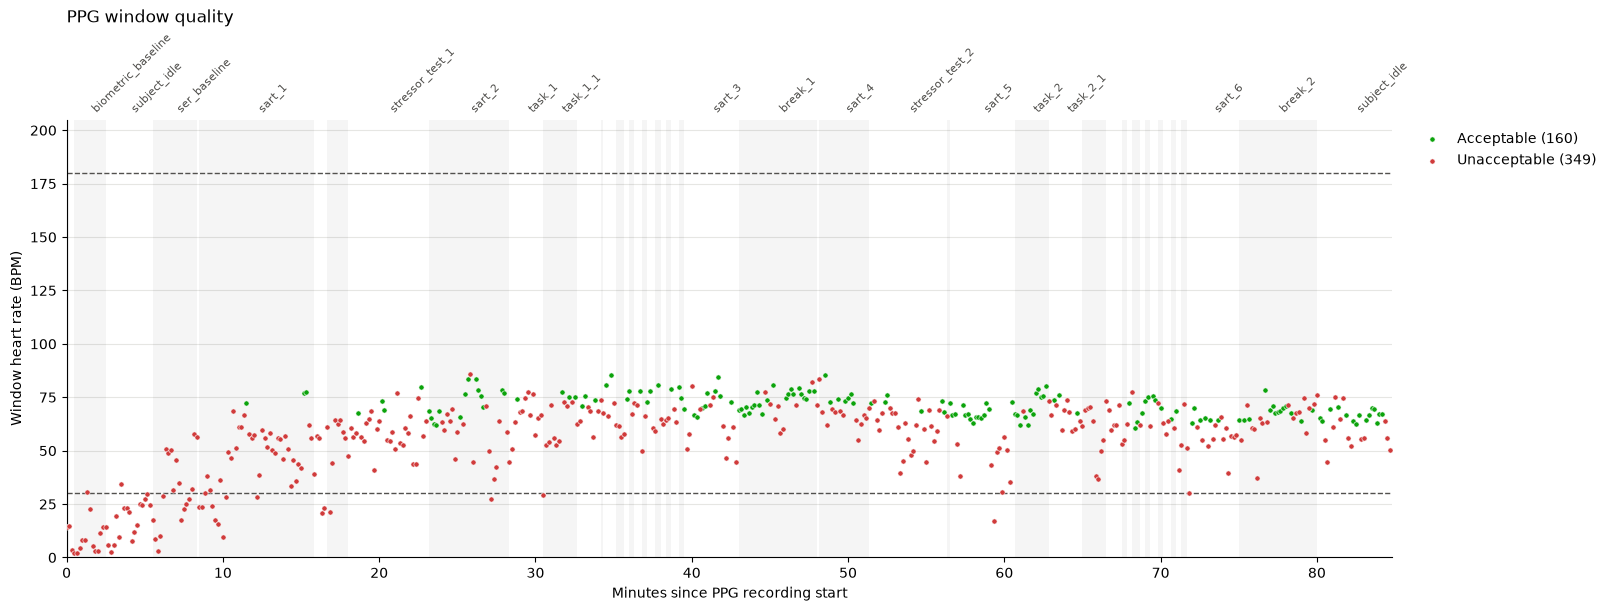

In [10]:
run_id = (windows["phase"] != windows["phase"].shift()).cumsum()
phase_segments = windows.groupby(run_id).agg(
    phase=("phase", "first"), start=("minutes", "first"), end=("minutes", "last")
).reset_index(drop=True)
phase_segments["end"] += WINDOW_S / 60

HR_PLOT_MAX = 200
fig, ax = plt.subplots(figsize=(16, 6), constrained_layout=True)
for i, seg in phase_segments.iterrows():
    if i % 2 == 0:
        ax.axvspan(seg["start"], seg["end"], color="#000000", alpha=0.04, lw=0)
for y in [HR_MIN_BPM, HR_MAX_BPM]:
    ax.axhline(y, color="#52514e", lw=1, ls="--")

for q in QUALITY_ORDER:
    pts = windows[windows["quality"] == q]
    ax.scatter(pts["minutes"], pts["hr_bpm"].clip(upper=HR_PLOT_MAX), s=14, color=QUALITY_COLORS[q],
               edgecolor="white", linewidth=0.4, zorder=3, label=f"{q} ({len(pts)})")

for _, seg in phase_segments.iterrows():
    if seg["end"] - seg["start"] >= 2:
        ax.text((seg["start"] + seg["end"]) / 2, 1.01, seg["phase"], transform=ax.get_xaxis_transform(),
                rotation=45, ha="left", va="bottom", fontsize=8, color="#52514e")

ax.set_xlim(0, windows["minutes"].iloc[-1] + WINDOW_S / 60)
ax.set_ylim(0, HR_PLOT_MAX + 5)
ax.set_xlabel("Minutes since PPG recording start")
ax.set_ylabel("Window heart rate (BPM)")
ax.set_title("PPG window quality", loc="left", pad=70)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

The same windows grouped into 10-minute blocks, to show how quality changes over the session.

In [11]:
ten_min_block = (windows["minutes"] // 10 * 10).astype(int).rename("block_start_min")
windows.groupby(ten_min_block).agg(
    windows=("quality", "size"),
    acceptable_pct=("quality", lambda q: round(100 * (q == "Acceptable").mean(), 1)),
    median_hr_bpm=("hr_bpm", "median"),
    median_beats_in_window=("beats_in_window", "median"),
).round(1)

,windows,acceptable_pct,median_hr_bpm,median_beats_in_window
block_start_min,,,,
0,60,0.0,22.1,4.0
10,60,6.7,55.9,9.0
20,60,30.0,63.9,11.0
30,60,30.0,67.9,11.5
40,60,58.3,71.3,12.0
50,60,38.3,65.8,11.0
60,60,40.0,67.3,11.0
70,60,38.3,64.3,11.0
80,29,51.7,64.3,11.0


### Quality By Phase
Share of each phase's windows that are Acceptable, with the number of windows in brackets. Phases are listed in the order they first occur. PRS questionnaire items last only ~22 seconds (2–3 windows each), so their shares are rough.

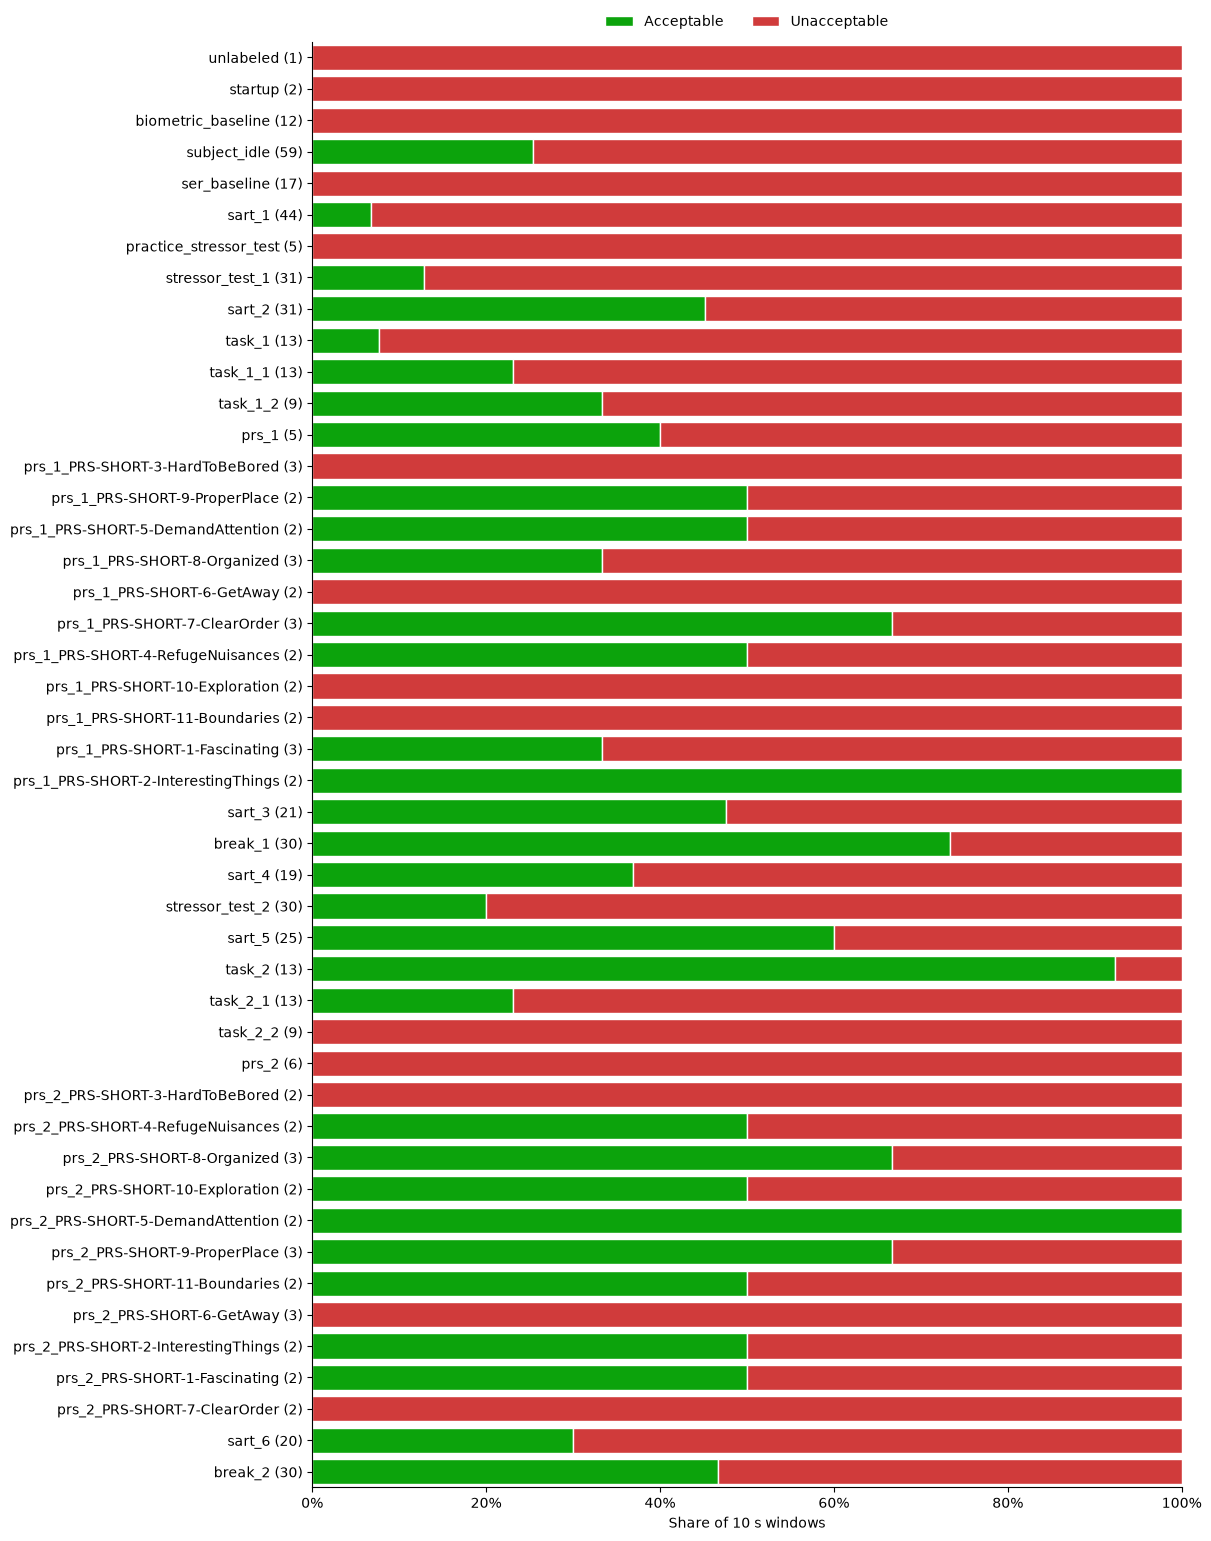

In [12]:
phase_order = list(dict.fromkeys(windows["phase"]))
quality_by_phase = pd.crosstab(windows["phase"], windows["quality"]).reindex(index=phase_order, columns=QUALITY_ORDER, fill_value=0)
shares = quality_by_phase.div(quality_by_phase.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 0.3 * len(phase_order) + 1.5), constrained_layout=True)
left = np.zeros(len(shares))
for q in QUALITY_ORDER:
    ax.barh(range(len(shares)), shares[q], left=left, color=QUALITY_COLORS[q], label=q, edgecolor="white", linewidth=1, height=0.8)
    left += shares[q].to_numpy()
ax.set_yticks(range(len(shares)), [f"{p} ({n})" for p, n in zip(shares.index, quality_by_phase.sum(axis=1))])
ax.set_ylim(len(shares) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Share of 10 s windows")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [13]:
quality_by_phase.assign(
    windows=quality_by_phase.sum(axis=1),
    acceptable_pct=(100 * shares["Acceptable"]).round(1),
    median_hr_bpm=windows.groupby("phase")["hr_bpm"].median().round(1),
    contains_movement=windows.groupby("phase")["contains_movement"].sum(),
)

quality,Acceptable,Unacceptable,windows,acceptable_pct,median_hr_bpm,contains_movement
phase,,,,,,
unlabeled,0,1,1,0.0,14.3,0
startup,0,2,2,0.0,9.2,0
biometric_baseline,0,12,12,0.0,6.8,0
subject_idle,15,44,59,25.4,56.3,0
ser_baseline,0,17,17,0.0,28.8,0
sart_1,3,41,44,6.8,49.9,0
practice_stressor_test,0,5,5,0.0,39.3,0
stressor_test_1,4,27,31,12.9,58.5,0
sart_2,14,17,31,45.2,65.3,3


### Observations
Each observation names the section whose output supports it.
- **The beat file is usable as a list of intervals** *(Loading & Dropping Columns)*: the 5041 beats are sorted with no duplicate timestamps. The time between consecutive beats matches `BI` to a median of 4 ms (99th percentile 20 ms), which supports Assumption 2. `LocalTimestamp` steps match `EmotiBitTimestamp` to within 0.36 ms. `DataReliability` is 100 on every row.
- **Only 31.4% of windows are Acceptable** *(Running The Checks)*: 160 of 509 windows pass all three checks, and they contain 37.5% of the beats *(PPG Mask For HRV Cleaning)*. The ratio check fails most often (66.8% of windows), then the gap check (21.4%) and the heart-rate check (10.6%). 240 of the 349 Unacceptable windows fail *only* the ratio check.
- **Failures are mostly missed beats, not extra beats** *(Running The Checks, ratio diagnostic)*: 313 of the 340 ratio-failing windows have an interval more than 1.5× the window's median, which is what a skipped beat looks like. Across the recording, 9.6% of all intervals are over 1.5 s, compared with 1.4% under 0.5 s. Every heart-rate failure is too *low* (all below 30 BPM, median 17.4), which is also what missed beats cause. None is too high.
- **Failing windows are far from the thresholds, so the result doesn't depend much on their exact values** *(Running The Checks, sensitivity)*: ratio-failing windows have a median ratio of 4.16, and gap-failing windows a median largest interval of 4.56 s. Moving the gap threshold between 2.5 and 3.5 s changes nothing, because every window that fails the gap check also fails another check. Loosening the ratio threshold has more effect (36.0% Acceptable at 2.5, 44.4% at 3.0), but most windows still fail.
- **Beat detection is very poor in the first ~20 minutes and improves later** *(Quality Over Time)*: 0% of windows are Acceptable in minutes 0–10 (median window heart rate 22.1 BPM, 4 beats per window), and 6.7% in minutes 10–20. From minute 20 onward it is 30–58% per block, with ~11–12 beats per window and a median heart rate of 64–71 BPM. Every window in `biometric_baseline`, `ser_baseline` and `practice_stressor_test` is Unacceptable, and `sart_1` is 6.8% Acceptable *(Quality By Phase)*.
- **Movement bursts explain very few failures** *(Cross-Check With Movement Bursts)*: only 12 windows contain a movement burst, and 10 of those are Unacceptable. That is 10 of the 349 Unacceptable windows. 68% of windows without movement also fail.
- **The PPG recording starts 5.3 s before the first biometrics marker** *(Attaching Experiment Phases)*, so the first window is `unlabeled`.

### Conclusions
- **Drop the Unacceptable windows from HRV. This leaves 31.4% of the recording.** *Reasoning:* the checks are applied as the source specifies, and the failing windows fail by a wide margin (see sensitivity), so they are not borderline cases.
- **The low pass rate is a problem with the EmotiBit's beat detection, not with the participant's heart rhythm.** *Reasoning:* the failures are dominated by long intervals and too-low heart rates, which is what missed beats look like. Movement explains almost none of them. A real heart doesn't jump from ~70 BPM to ~20 BPM and back within a window.
- **The baseline phases (`biometric_baseline`, `ser_baseline`) have no usable HRV from the device's beats.** *Reasoning:* every window in them is Unacceptable. This matters because baselines are normally the reference for the other phases. It is the main limitation of this mask for later analysis.
- **Detecting peaks ourselves in PPG Green is worth trying as a next step.** *Reasoning:* the failures come from the device's beat detector skipping beats, so the PPG signal itself may still contain those beats. Detecting peaks directly in `PG` (the channel recommended for HRV in the notes above) and running the same checks would show whether more of the recording, especially the first 20 minutes, can be recovered. This hasn't been tested yet.

### PPG Mask For HRV Cleaning
One row per 10 s window. `keep` is True for Acceptable windows. The check values and results are kept so `999_hrv-cleaning.ipynb` can see why a window failed.

Columns: `window_start`, `window_end` (same clock as `timestamp_unix` in the biometrics file and `LocalTimestamp` in the movement mask), `beats_in_window`, `hr_bpm`, `max_gap_s`, `interval_ratio`, `hr_ok`, `gap_ok`, `ratio_ok`, `ppg_quality`, `keep`. To attach it to HR/BI rows, give each row the window where `window_start <= LocalTimestamp < window_end`.

In [14]:
ppg_mask = windows[["window_start", "window_end", "beats_in_window", "hr_bpm", "max_gap_s", "interval_ratio"] + CHECKS].copy()
ppg_mask["ppg_quality"] = windows["quality"]
ppg_mask["keep"] = ppg_mask["ppg_quality"] == "Acceptable"

print(f"Kept: {ppg_mask['keep'].sum()} of {len(ppg_mask)} windows ({100 * ppg_mask['keep'].mean():.1f}%)")
beat_window = np.searchsorted(ppg_mask["window_start"], beat_t, side="right") - 1
print(f"Beats inside kept windows: {100 * ppg_mask['keep'].to_numpy()[beat_window].mean():.1f}%")

MASK_OUTPUT_FILE.parent.mkdir(exist_ok=True)
ppg_mask.to_csv(MASK_OUTPUT_FILE, index=False)
ppg_mask.head()

Kept: 160 of 509 windows (31.4%)
Beats inside kept windows: 37.5%


,window_start,window_end,beats_in_window,hr_bpm,max_gap_s,interval_ratio,hr_ok,gap_ok,ratio_ok,ppg_quality,keep
0,1.757035e+09,1.757035e+09,2,14.319809,7.14,6.932039,False,False,False,Unacceptable,False
1,1.757035e+09,1.757035e+09,3,14.916097,7.14,6.550459,False,False,False,Unacceptable,False
2,1.757035e+09,1.757035e+09,1,3.572492,29.67,7.568878,False,False,False,Unacceptable,False
3,1.757035e+09,1.757035e+09,0,2.022245,29.67,1.000000,False,False,True,Unacceptable,False
4,1.757035e+09,1.757035e+09,0,2.022245,29.67,1.000000,False,False,True,Unacceptable,False
